In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os
from pathlib import Path
try:
  import google.colab
  USING_COLAB = True
except:
  USING_COLAB = False

if USING_COLAB:

  os.chdir("/content")
  os.system("git clone https://github.com/src47/multibax-sklearn.git")
  os.chdir("multibax-sklearn")
  sys.path.extend(["/content/multibax-sklearn"])
  ! pip install python-ternary
else:
  os.chdir("../../") # cell can only be run once!

Mounted at /content/drive


Load data (Note this is some fake simulated data based on Makenna's 4 datapoints). I basically just fit a quadractic to both curves and used it to generate some points.


In [2]:
datapath = "/content/drive/Shared drives/BAX_catalyst/data/3D_data1A1.csv"


In [3]:
%load_ext autoreload
%autoreload 2

import warnings
import os

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
from sklearn.gaussian_process.kernels import WhiteKernel, ConstantKernel, Matern, RBF
from sklearn.preprocessing import MinMaxScaler
import ipywidgets as widgets
from IPython.display import display


from src.utils import XY_from_csv, random_sampling_no_replace, load_ternary_data
from src.acquisition import run_acquisition
from src.algorithms import MultibandUnion, ConditionalMultiband, MultibandIntersection, ParetoPlusMultiband, ParetoFront, Wishlist, PercentileSet1D
from src.models import MGPR, fit_matern_hypers
from src.metrics import get_n_obtained, get_jaccard_posterior
from src.plotting import plot_final_metrics, plot_iteration_results, plot_algo_true_function

plt.style.use("src/matplotlib.rc")
warnings.filterwarnings('ignore')

In [4]:
import numpy as np
add_noise = False
X, Y = XY_from_csv(datapath, columns_x=['Time', 'Temperature', 'Pressure'], columns_y=['Yield', 'Median'])
# X = np.expand_dims(X, axis = -1) # bug in the code above which requires me to load in time twice and then only pick one column
Y_noise_less = Y.copy()
if add_noise:
  # Just added a little bit of noise for more realistic setting
  sigma = np.std(Y, axis=0)/3
  noise = sigma * np.random.randn(Y.shape[0], Y.shape[1])
  Y = Y + noise

In [5]:
Y.shape

(504, 2)

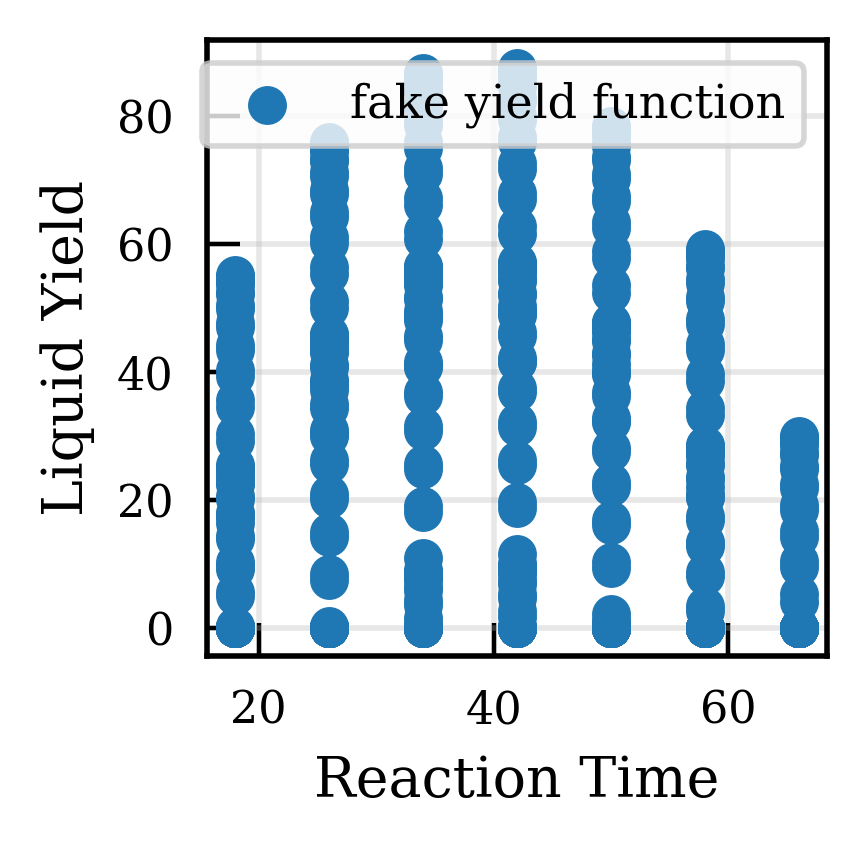

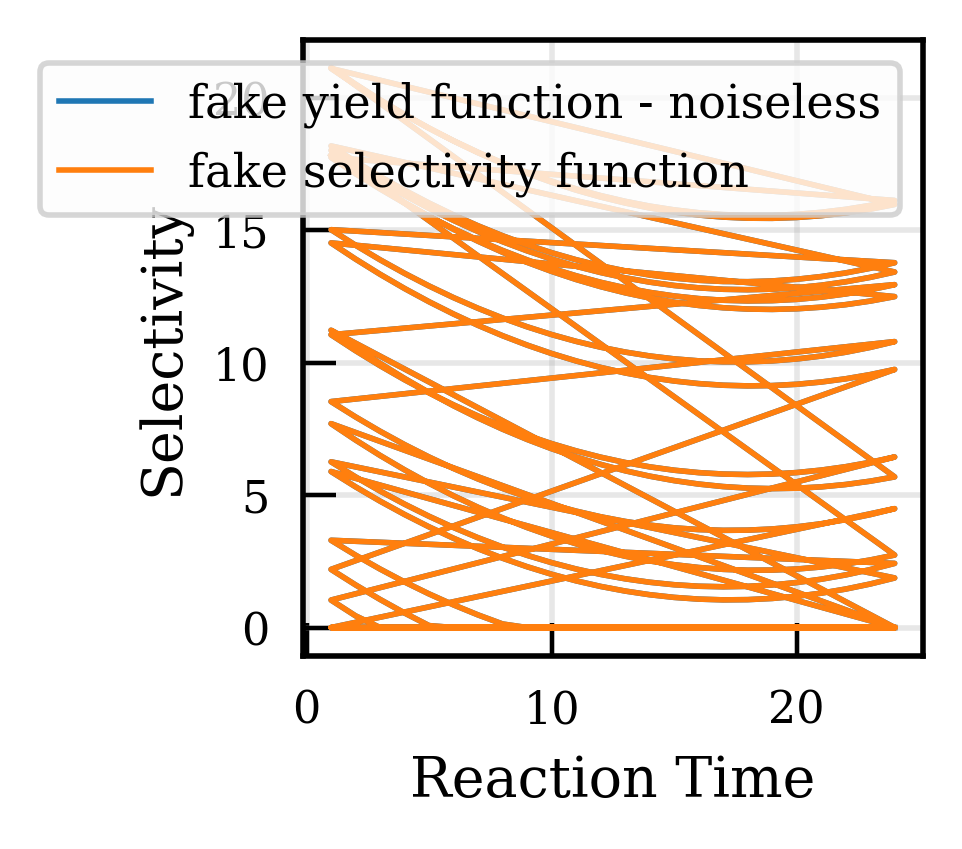

In [6]:
plt.figure(figsize=(2, 2))
# plt.plot(X[:,0], Y_noise_less[:,0],"-",label = 'fake yield function - noiseless')
plt.scatter(X[:,2], Y[:,0], label = 'fake yield function')
plt.xlabel('Reaction Time')
plt.ylabel('Liquid Yield')
plt.legend()

plt.show()

plt.figure(figsize=(2, 2))
plt.plot(X[:,0], Y_noise_less[:,1],"-",label = 'fake yield function - noiseless')
plt.plot(X[:,0], Y[:,1], label = 'fake selectivity function')
plt.xlabel('Reaction Time')
plt.ylabel('Selectivity')
plt.legend()
plt.show()

In [7]:
# Technically we shouldn't be able to normalize since we have collected any data; will fix this up
# Fixed this

x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(-1, 1))

scalers = [x_scaler, y_scaler]

X_norm = x_scaler.fit_transform(X)
# Y_norm = y_scaler.fit_transform(Y) # Ideal Normalization

# Normalization based on parameters
yield_min = 0
yield_max = 100
selectivity_min = 8
selectivity_max = 20

y_scaler.fit(np.array([[yield_min, selectivity_min],[yield_max, selectivity_max]]))
Y_norm = y_scaler.fit_transform(Y)

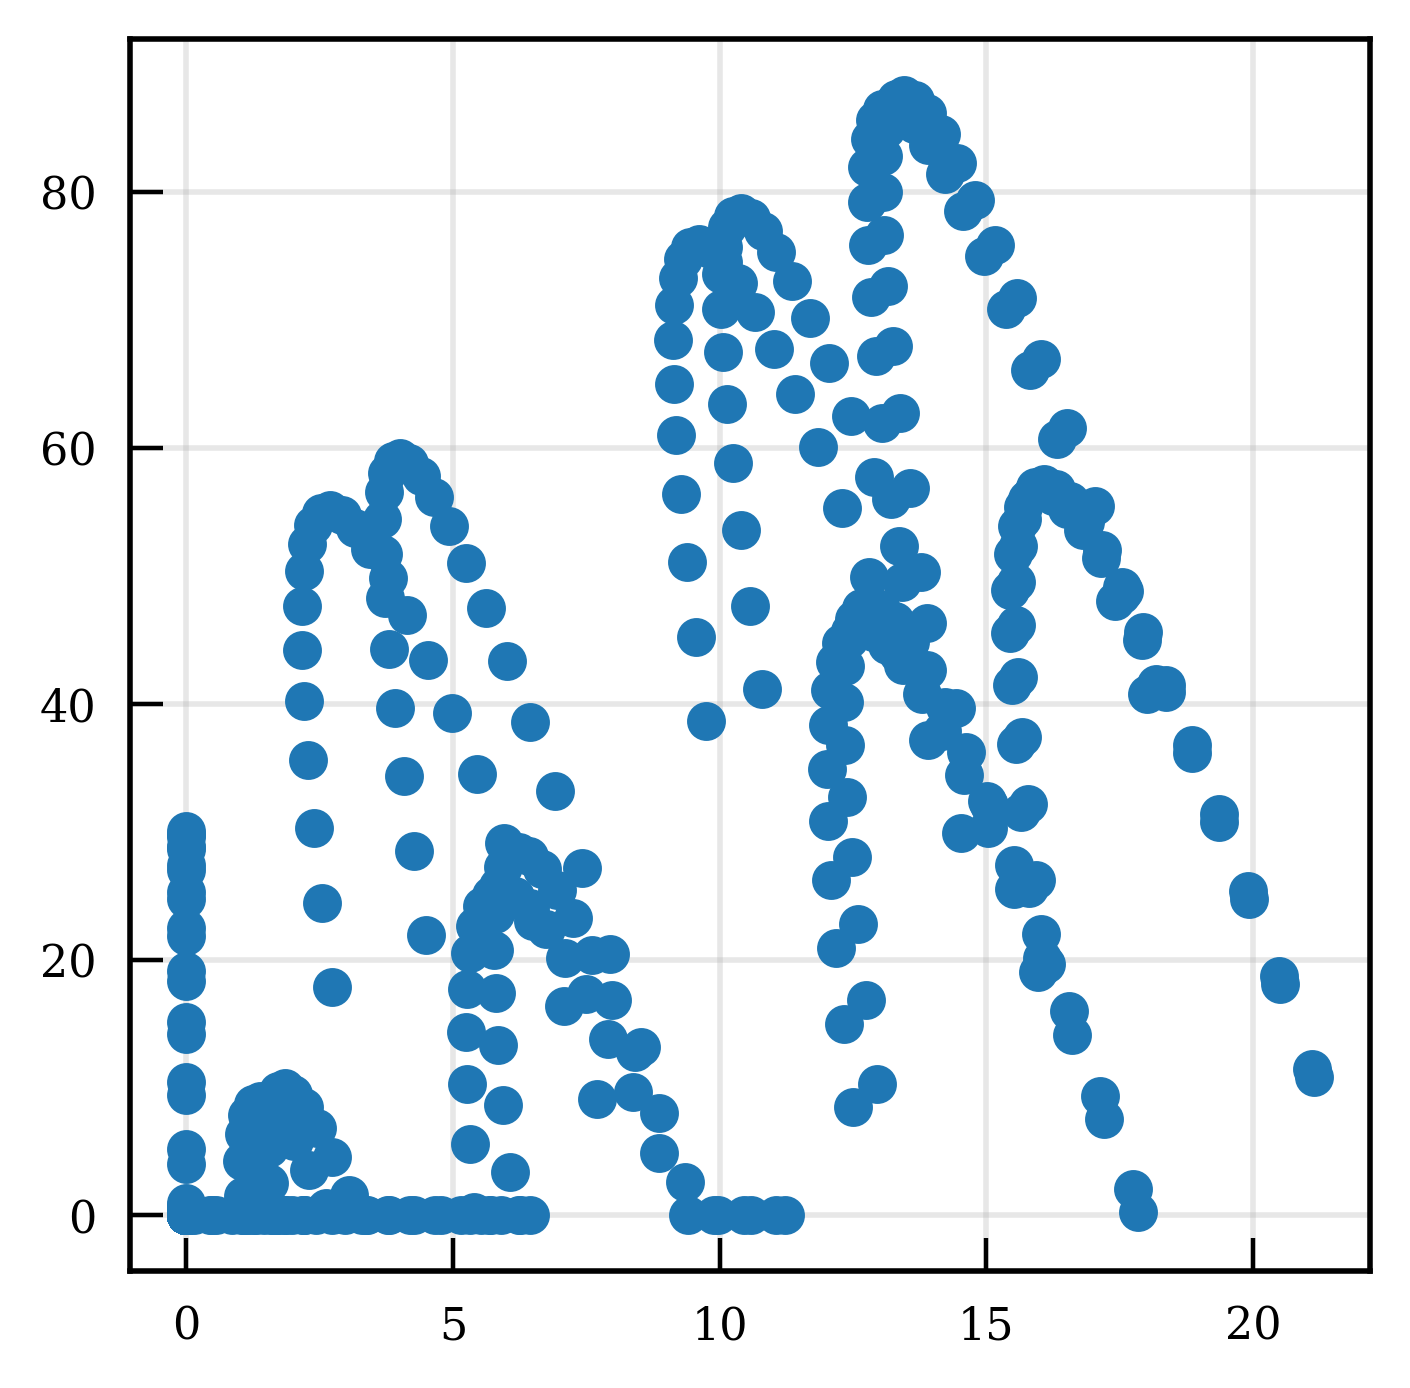

In [8]:
plt.scatter(Y[:,1], Y[:,0])

In [9]:
from src.algorithms import SubsetAlgorithm

class MaxBinAlgorithm(SubsetAlgorithm):
    def __init__(self, user_algo_params):
        super().__init__(user_algo_params)

    def user_algorithm(self, f_x, x):
        bin_size = self.user_algo_params["bin_size"]
        try:
          list_of_max_ids = []

          f_1 = f_x[:,0] # only take the first property column, yield
          f_2 = f_x[:,1] # only take the first property column, median

          for i in range(0, 9, 2):
            ids1 = set(np.where(f_2 >= 9 + i)[0])
            ids2 = set(np.where(f_2 <= 10 + i)[0])
            ids3 = list(ids1.intersection(ids2))
            vals = f_1[ids3]
            num_list = [np.argmax(vals)]
            max_id = ids3[num_list[0]]
            list_of_max_ids.append(max_id)

          return list(set(list_of_max_ids))
        except:
          return []




# class LevelBandAlgorithm(SubsetAlgorithm):
#     def __init__(self, user_algo_params):
#         super().__init__(user_algo_params)

#     def user_algorithm(self, f_x, x):
#         a = self.user_algo_params["a"]
#         b = self.user_algo_params["b"]

#         c = self.user_algo_params["c"]
#         d = self.user_algo_params["d"]

#         f_1 = f_x[:,0] # only take the first property column
#         f_2 = f_x[:,1] # only take the second property column
#         ids1 = set(np.where(f_1 >= a)[0]) # the set of ids where f_1 is bigger/equal to a
#         ids2 = set(np.where(f_1 <= b)[0]) # the set of ids where f_2 is bigger/equal to b
#         ids_both = ids1.intersection(ids2) # the set of ids that match both conditions. i.e. a <= f_1 <= b

#         ids_both1

#         final_ids= ids_both.union(ids_both1)


#         return list(ids_both)

In [10]:
algorithm=MaxBinAlgorithm(user_algo_params = {"scalers": scalers, "bin_size": 2})
#algorithm=LevelBandAlgorithm(user_algo_params = {"scalers": scalers, "a": 10.0, "b": 40})


In [11]:
all_ids = list(np.arange(0, len(X_norm)))  # integer mapping design space
true_target_ids = algorithm.identify_subspace(f_x=Y_norm, x=X_norm)


In [12]:
Y[true_target_ids]

array([[75.93652,  9.6129 ],
       [75.352  , 11.061  ],
       [55.49784, 17.0297 ],
       [75.85696, 15.1649 ],
       [87.56164, 13.4657 ]])

In [13]:
# plt.figure(figsize=(3, 3))
# plt.scatter(X, Y[:,0], label = 'fake yield function')
# plt.xlabel('Reaction Time')
# plt.ylabel('Liquid Yield')
# plt.scatter(X, Y[:,1], label = 'fake selectivity function')
# plt.xlabel('Reaction Time')
# plt.ylabel('Selectivity / Liquid Yield')

# for i in true_target_idos:
#   plt.axvline(x = X[i], color = 'b')

# plt.show()

In [14]:
len(X)

504

In [15]:
n_features = 3 # change to 3
n_properties = 2

kernel_initial = ConstantKernel(constant_value=1.0, constant_value_bounds=[0.01, 3.0]) * Matern(nu = 5/2, length_scale= n_features * [1.0], length_scale_bounds= n_features * [[0.01, 3.0]]) + WhiteKernel(noise_level=0.01, noise_level_bounds='fixed')
kernel_initial_list = n_properties * [kernel_initial]


In [19]:
plotting = True
prevent_requery = True # (default this somewhere else)
n_posterior_samples = 15 # relevant for InfoBAX and mixedBAX ~ generally 10-15 is a good number
n_initial = 1# Number of initial datapoints
n_iters = 40 # Number of measurements to be performed
plot_frequency = 50
n_repeats = 1 # Repeats with different dataset initializations
fixed_hypers = True # true uses pre-fixed hypers fit to the entire dataset
adaptive_fit_freq = 10 # Frequency to fit hypers; only applies if fixed_hypers = False


In [20]:
X

array([[  1, 200,  26],
       [  2, 200,  26],
       [  3, 200,  26],
       ...,
       [ 22, 250,  66],
       [ 23, 250,  66],
       [ 24, 250,  66]])

Using strategy: SwitchBAX, repeat number: 0


100%|██████████| 40/40 [00:20<00:00,  1.98it/s]


Using strategy: US, repeat number: 0


100%|██████████| 40/40 [00:00<00:00, 68.33it/s]


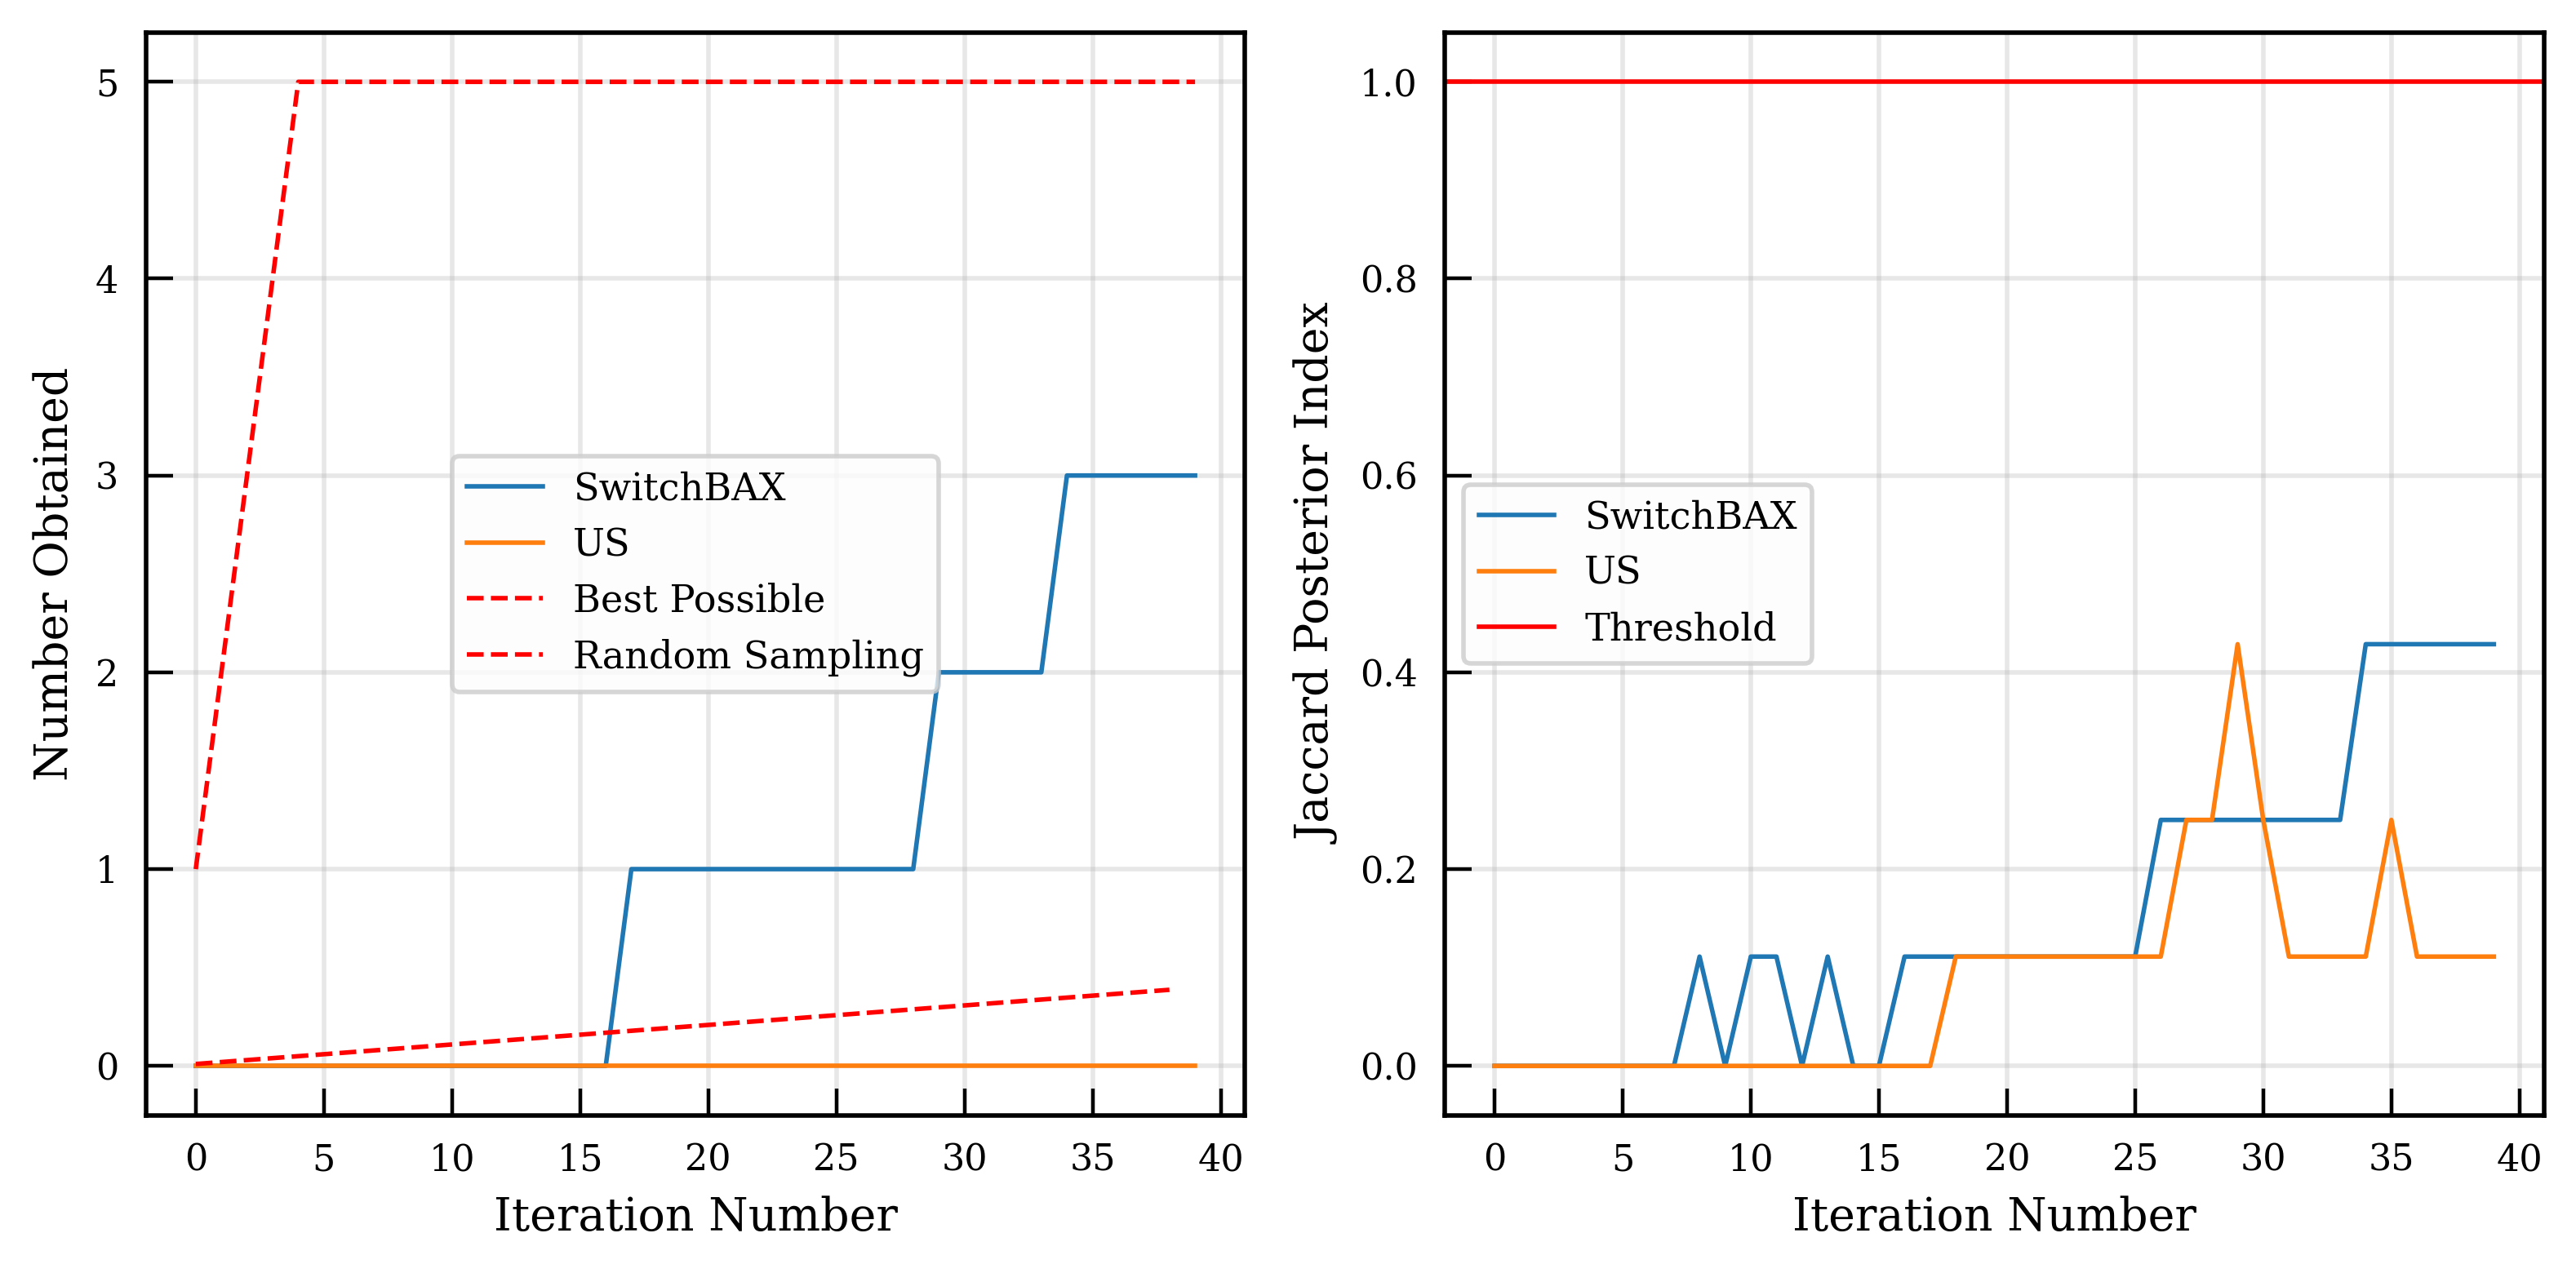

In [21]:
metrics = {
    "SwitchBAX": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
    "US": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
    "MeanBAX": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
    "InfoBAX": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
}

# Baseling for random sampling without replacement (expectation of hypergeometric distribution)
random_sampling = [random_sampling_no_replace(len(X_norm), len(true_target_ids), n) for n in range(n_initial, n_iters)]

# Baseline for best possible acquisition (i.e. acquire a target point at each iteration; need an "oracle" to do this)
if n_iters <= len(true_target_ids):
    best_possible_n_obtained = np.arange(n_initial, n_iters + n_initial)
else:
    best_possible_n_obtained = list(np.arange(n_initial, len(true_target_ids))) + list(
        len(true_target_ids) * np.ones(n_iters + n_initial - len(true_target_ids))
    )

# Acquisition functions that use BAX for subset estimation
# strategies = ["SwitchBAX", "US", "InfoBAX"]
strategies = ["SwitchBAX", "US"]

# Calculate hypers based on the entire dataset; this is not possible in a real experiment but allows us to compare acquisition fn to acquisition fn
if fixed_hypers: kernel_list = fit_matern_hypers(x_train=X_norm, y_train=Y_norm, kernel_list=kernel_initial_list, n_restarts_optimizer=1)

for strategy in strategies:
    for j in range(n_repeats):  # to see variance w.r.t initial datapoint choice

        print("Using strategy: {}, repeat number: {}".format(strategy, j))

        np.random.seed(j) # make sure all strategies get same initial points
        train_indices = list(np.random.choice(all_ids, n_initial))
        x_train = X_norm[train_indices]
        y_train = Y_norm[train_indices]

        collected_ids = list(train_indices)
        n_obtained_list = []
        jaccard_posterior_list = []
        switch_list = []

        for i in tqdm(range(n_iters)):
            # Adaptive hyperparameter fitting
            if (i % adaptive_fit_freq == 0) and (fixed_hypers == False):
                kernel_list = fit_matern_hypers(x_train=x_train, y_train=y_train, kernel_list=kernel_initial_list)

            # Define GP model with fixed, fitted hypers. Note, we need this so that all the n_posterior models for InfoBAX have the same kernel
            multi_gpr = MGPR(kernel_list=kernel_list)

            # Acquire next index
            x_train, y_train, model, collected_ids, acquisition_function, switch_strategy = run_acquisition(
                x_train, y_train, X_norm, Y_norm, strategy, algorithm, multi_gpr, collected_ids, n_posterior_samples
            )

            # Calculate metrics
            posterior_mean, posterior_std = model.predict(X_norm)


            predicted_target_ids = algorithm.identify_subspace(f_x = posterior_mean, x=X_norm)
            n_obtained_list.append(get_n_obtained(collected_ids, true_target_ids))
            jaccard_posterior_list.append(get_jaccard_posterior(predicted_target_ids, true_target_ids))
            switch_list.append(switch_strategy)

            if (i % plot_frequency == 0) and (plotting) and (i != 0):

                for k in range(2):
                  plt.plot(X_norm, posterior_mean[:,k], color = 'blue')
                  plt.plot(X_norm, Y_norm[:, k], color = 'red')
                  plt.fill_between(X_norm[:,0], posterior_mean[:,k] - 1.96 * posterior_std[:,k], y2=posterior_mean[:,k] + 1.96 * posterior_std[:,k], alpha = 0.1)
                  plt.scatter(x_train, y_train[:,k], color = 'k')

                  for i in true_target_ids:
                    plt.axvline(x = X_norm[i], color = 'green')
                  plt.show()


                plot_iteration_results(
                    np.hstack((X_norm, X_norm)),
                    Y_norm,
                    x_scaler,
                    y_scaler,
                    collected_ids,
                    true_target_ids,
                    predicted_target_ids,
                    acquisition_function,
                    n_obtained_list,
                    jaccard_posterior_list,
                    best_possible_n_obtained,
                    random_sampling,
                    n_initial
                )

        metrics[strategy]["n_obtained"].append(n_obtained_list)
        metrics[strategy]["jaccard_posterior_index"].append(jaccard_posterior_list)
        metrics[strategy]["switch_strategy"].append(switch_list)

plot_final_metrics(n_iters, metrics, strategies, best_possible_n_obtained, random_sampling)


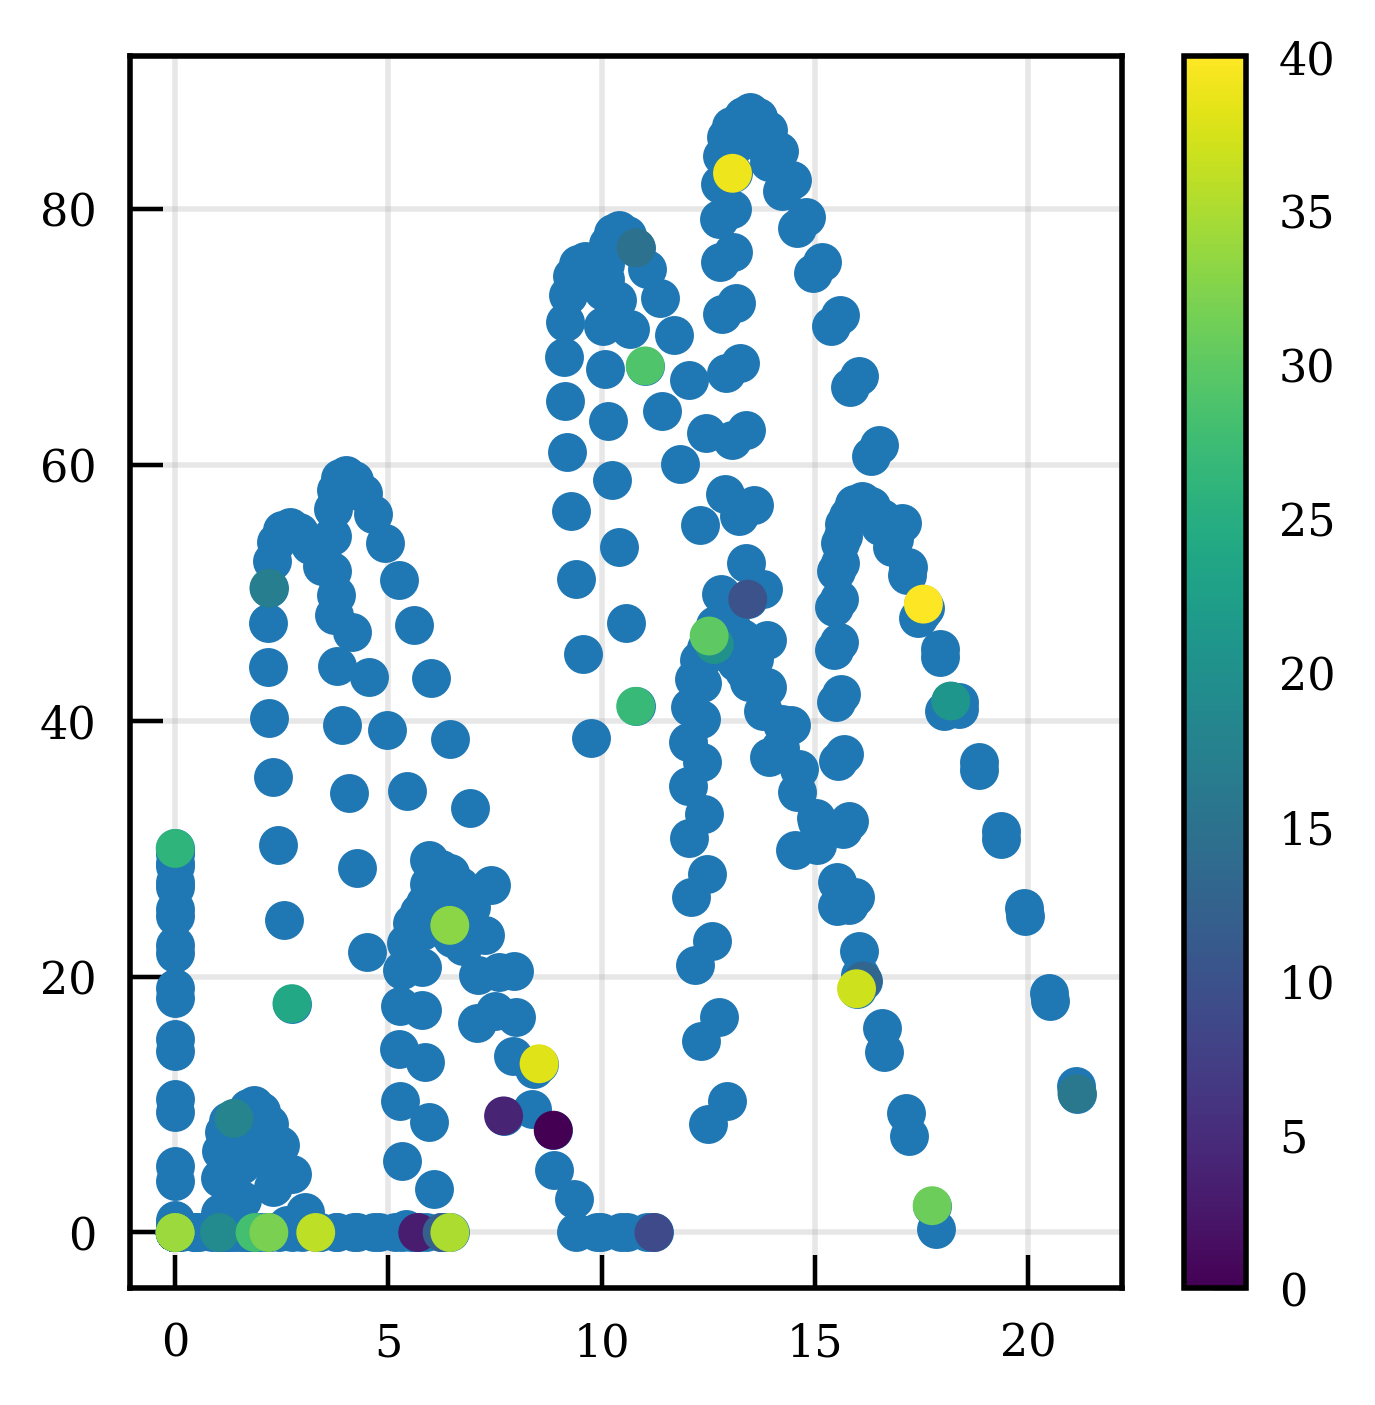

In [22]:
plt.scatter(Y[:,1], Y[:, 0])
plt.scatter(Y[collected_ids, 1], Y[collected_ids, 0], c=np.arange(len(collected_ids)))
plt.colorbar()
plt.show()


ValueError: operands could not be broadcast together with shapes (504,6) (3,) (504,6) 

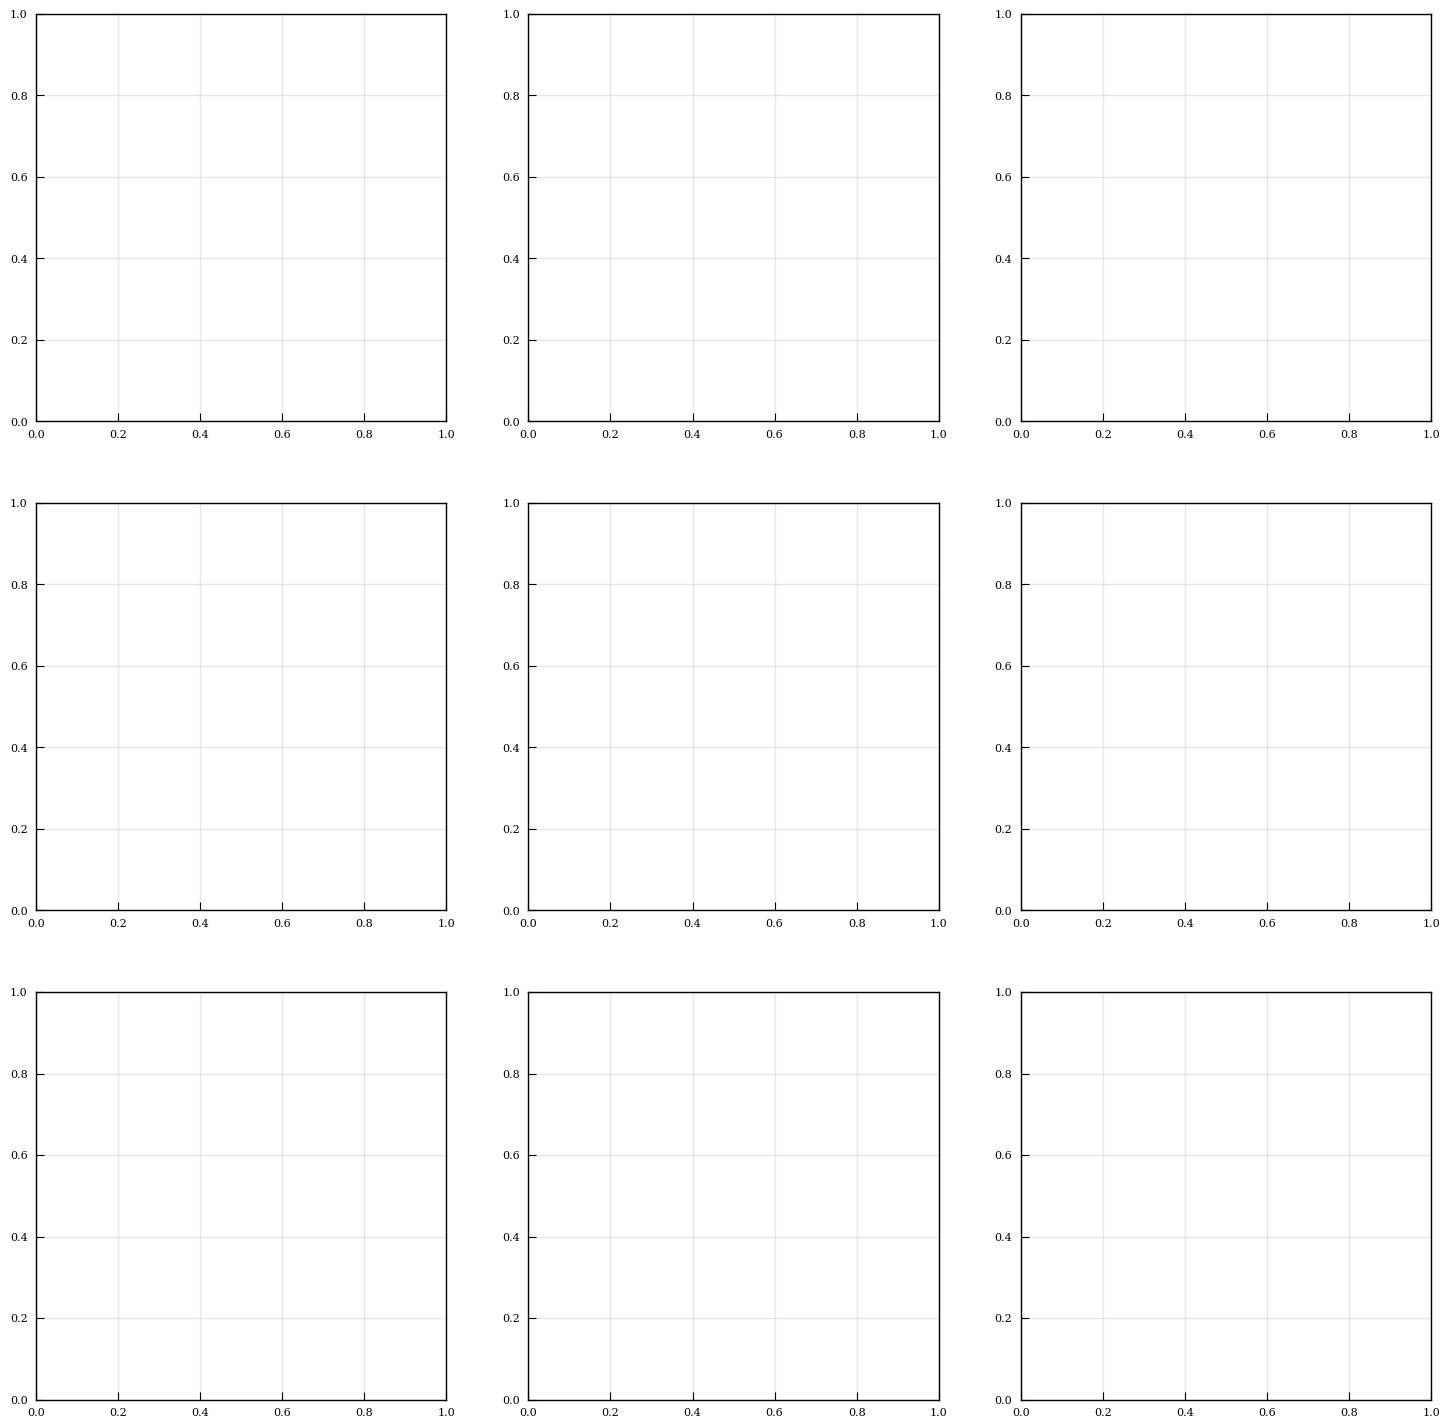

In [23]:
plot_iteration_results(
                    np.hstack((X_norm, X_norm)),
                    Y_norm,
                    x_scaler,
                    y_scaler,
                    collected_ids,
                    true_target_ids,
                    predicted_target_ids,
                    acquisition_function,
                    n_obtained_list,
                    jaccard_posterior_list,
                    best_possible_n_obtained,
                    random_sampling,
                    n_initial
                )